# 00 · Cadrer le problème

*Module 14 « Feature engineering & transformation » · TD du mercredi 21 octobre 2026 · AMA, UE Ingénierie des données*

**Ce qu'on fait.** Avant de créer la moindre variable, on fixe les règles du jeu, communes aux quatre approches des
notebooks 01 à 04 : ce qu'on prédit, à quel moment, avec quelles colonnes, comment on découpe les données et
comment on note un modèle. Chaque règle s'appuie sur une mesure : une fuite qui donne une AUC de 1, un découpage au
hasard qui flatte le score, un modèle « qui ne fait rien » à battre.

**Les choix de cette approche**

| Décision | Choix | Pourquoi |
|---|---|---|
| Moment de la prédiction | la réservation | c'est là que l'hôtel peut agir (surréservation, relance, acompte) ; ce qui arrive après est interdit |
| Cible | `is_canceled` : 1 = annulée, absences (« No-Show ») comprises | une chambre vide coûte la même chose, que le client ait annulé ou ne soit pas venu |
| Fuites | cinq colonnes retirées : `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `required_car_parking_spaces` | inconnues à l'instant de la réservation (cours 1, slide 8) |
| Année d'arrivée | `arrival_date_year` écartée | un modèle mis en service en 2017 ne reverra jamais 2015 |
| Découpage | temporel, 80/20 sur la date d'arrivée, coupure le 22 avril 2017 | on entraîne sur le passé, on teste sur la suite, comme en production (cours 1, slide 9) |
| Métrique principale | AUC ROC, avec la précision moyenne et l'exactitude au seuil 0,5 | l'AUC juge le classement des réservations, sans avoir à choisir un seuil |
| Score à battre | un `DummyClassifier` et un modèle à une seule variable (`lead_time`) | savoir ce que vaut « ne rien faire » avant de se réjouir d'un score |

**Les outils utilisés**

- `fe_tp.donnees.charger` et `decouper` (le paquet du TD) ; `hashlib.sha256` pour l'empreinte du fichier.
- `pd.crosstab`, `groupby(...).agg(...)` : le crible des fuites (cours 1, slides 8 et 10).
- `ColumnTransformer`, `make_pipeline`, `SimpleImputer`, `OneHotEncoder(handle_unknown="infrequent_if_exist",
  min_frequency=20)` (cours 1, slides 20 et 21 ; cours 2, slide 24) et `HistGradientBoostingClassifier`
  (cours 2, slide 28).
- `train_test_split(..., stratify=y)` contre le découpage temporel, puis `TimeSeriesSplit` (cours 1, slide 9).
- `DummyClassifier`, `LogisticRegression` précédée d'un `StandardScaler` (cours 1, slide 7) ; `roc_auc_score`,
  `average_precision_score`, `accuracy_score`, `roc_curve` (`sklearn.metrics`).

**Ce qu'on regarde à la fin.** Un tableau « score à battre » (AUC ROC, précision moyenne, exactitude sur le test),
qui sert de repère aux approches A à D, et la liste des colonnes autorisées.

In [1]:
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from fe_tp.donnees import CATEGORIELLES, CIBLE, ECARTEES, FICHIER, FUITES, NUMERIQUES, charger, decouper

## 1. Charger les données

On vérifie d'abord qu'on travaille sur le bon fichier : son empreinte SHA-256 doit être celle notée dans
`data/SHA256SUMS.txt`. Un seul octet modifié, et l'empreinte n'a plus rien à voir.

In [2]:
calculee = hashlib.sha256(FICHIER.read_bytes()).hexdigest()
attendues = (FICHIER.parents[1] / "SHA256SUMS.txt").read_text()
print(calculee)
print("Conforme à data/SHA256SUMS.txt :", f"{calculee}  raw/hotels.csv" in attendues)

7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06
Conforme à data/SHA256SUMS.txt : True


L'empreinte `7c2ae42a…` est la bonne : vous travaillez tous sur le même fichier, vous obtiendrez donc les mêmes
chiffres.

`charger()` lit le fichier, ajoute trois dates (arrivée, réservation = arrivée − `lead_time` jours, clôture) et
retire les lignes impossibles. Comparons avec le fichier brut.

In [3]:
brut = pd.read_csv(FICHIER)
personnes = brut["adults"] + brut["children"].fillna(0) + brut["babies"]
print("Fichier brut   :", brut.shape)
print("0 personne :", (personnes == 0).sum(), "· adr hors de [0, 1000] :", (~brut["adr"].between(0, 1000)).sum())
df = charger()
print("Après charger():", df.shape)

Fichier brut   : (119390, 32)
0 personne : 180 · adr hors de [0, 1000] : 2


Après charger(): (119208, 36)


Le fichier brut compte 119 390 réservations et 32 colonnes. On retire 180 réservations sans aucune personne et
2 prix aberrants : il reste 119 208 lignes et 36 colonnes, les 32 d'origine plus `reservation_id` et les trois
dates `date_arrivee`, `date_reservation` et `date_cloture`.

In [4]:
apercu = ["hotel", "date_reservation", "date_arrivee", "lead_time", "stays_in_week_nights", "adults",
          "country", "market_segment", "deposit_type", "adr", "is_canceled"]
df[apercu].head()

,hotel,date_reservation,date_arrivee,lead_time,stays_in_week_nights,adults,country,market_segment,deposit_type,adr,is_canceled
0,Resort Hotel,2014-07-24,2015-07-01,342,0,2,PRT,Direct,No Deposit,0.0,0
1,Resort Hotel,2013-06-24,2015-07-01,737,0,2,PRT,Direct,No Deposit,0.0,0
2,Resort Hotel,2015-06-24,2015-07-01,7,1,1,GBR,Direct,No Deposit,75.0,0
3,Resort Hotel,2015-06-18,2015-07-01,13,1,1,GBR,Corporate,No Deposit,75.0,0
4,Resort Hotel,2015-06-17,2015-07-01,14,2,2,GBR,Online TA,No Deposit,98.0,0


Les lignes sont triées par date d'arrivée : les cinq premières arrivent le 1er juillet 2015 au Resort Hotel. La
deuxième a été réservée le 24 juin 2013, 737 jours avant l'arrivée : `date_reservation` est bien recalculée à partir
de `lead_time`.

## 2. La cible : `is_canceled`

`is_canceled` vaut 1 quand la réservation n'a pas abouti : annulée, ou client absent (« No-Show »). On regarde son
taux global, par hôtel, puis dans le temps.

In [5]:
print(f"Taux d'annulation global : {df[CIBLE].mean():.3f}")
df.groupby("hotel")[CIBLE].agg(["size", "mean"]).round(3)

Taux d'annulation global : 0.371


,size,mean
hotel,,
City Hotel,79162,0.418
Resort Hotel,40046,0.278


Plus d'une réservation sur trois n'aboutit pas (37,1 %). L'écart entre les hôtels est net : 41,8 % pour le City
Hotel de Lisbonne (79 162 réservations), 27,8 % pour le Resort Hotel de l'Algarve (40 046).

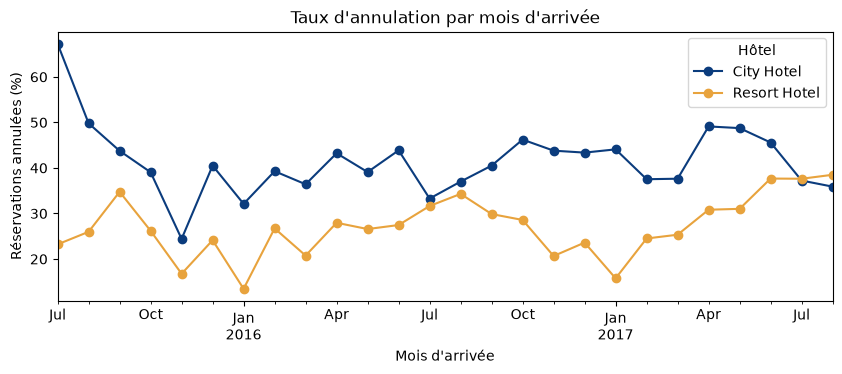

In [6]:
mensuel = df.groupby([df["date_arrivee"].dt.to_period("M"), "hotel"])[CIBLE].mean().unstack() * 100
ax = mensuel.plot(figsize=(10, 3.5), marker="o", color=["#0B3C7D", "#E8A33D"])
ax.set(title="Taux d'annulation par mois d'arrivée", xlabel="Mois d'arrivée", ylabel="Réservations annulées (%)")
ax.legend(title="Hôtel")
plt.show()

Le City Hotel reste au-dessus du Resort, sauf en juillet et août 2017, et le taux bouge beaucoup d'un mois à
l'autre : de 24 % à 67 % pour le City, de 13 % à 38,5 % pour le Resort. Pour le Resort, le taux monte nettement à l'été
2017 : la période qu'on voudra prédire ne ressemble pas tout à fait au passé.

## 3. Le crible des fuites

Pour chaque colonne, la question réflexe du cours (cours 1, slides 8 et 10) : **« Cette valeur était-elle connue à
l'instant de la réservation ? »** On ne fait ici qu'inspecter le sens des colonnes, sur tout le fichier : aucun
modèle n'apprend. Première suspecte, `reservation_status`.

In [7]:
pd.crosstab(df["reservation_status"], df[CIBLE])

is_canceled,0,1
reservation_status,,
Canceled,0,42992
Check-Out,75010,0
No-Show,0,1206


« Canceled » (42 992) et « No-Show » (1 206) donnent toujours 1, « Check-Out » (75 010) toujours 0 :
`reservation_status` est la cible écrite en toutes lettres. Les autres suspectes sont plus discrètes : pour
chacune, une condition, et le taux d'annulation selon qu'elle est vraie ou fausse.

In [8]:
suspects = {
    "date de clôture < date d'arrivée": df["date_cloture"] < df["date_arrivee"],
    "chambre attribuée ≠ chambre réservée": df["assigned_room_type"] != df["reserved_room_type"],
    "booking_changes > 0": df["booking_changes"] > 0,
    "required_car_parking_spaces ≥ 1": df["required_car_parking_spaces"] >= 1,
}
lignes = []
for nom, vrai in suspects.items():
    lignes.append({"condition": nom, "réservations": vrai.sum(),
                   "taux si vrai": df.loc[vrai, CIBLE].mean(), "taux si faux": df.loc[~vrai, CIBLE].mean()})
pd.DataFrame(lignes).set_index("condition").round(3)

,réservations,taux si vrai,taux si faux
condition,,,
date de clôture < date d'arrivée,42128,1.000,0.027
chambre attribuée ≠ chambre réservée,14795,0.054,0.416
booking_changes > 0,17976,0.157,0.409
required_car_parking_spaces ≥ 1,7409,0.000,0.395


Quatre signaux trop nets pour être honnêtes :

- **`reservation_status_date`** (ici `date_cloture`) est la date de l'issue : quand elle précède l'arrivée
  (42 128 réservations), c'est une annulation dans 100 % des cas, contre 2,7 % sinon.
- **`assigned_room_type`** est attribuée au check-in : un client présent est souvent surclassé ou déplacé. Chambre
  différente : 5,4 % d'annulations, contre 41,6 %.
- **`booking_changes`** compte les modifications faites *après* la réservation ; à l'instant de la réservation,
  elle vaut 0. Avec au moins une modification : 15,7 %, contre 40,9 %.
- **`required_car_parking_spaces`** est saisie à l'arrivée : seul un client venu demande une place. 0 % d'annulation
  sur les 7 409 réservations concernées.

**Trop beau pour être vrai.** Mesurons ce que ces colonnes font à un modèle. Le même pipeline (colonnes brutes,
one-hot, gradient boosting) est entraîné trois fois : sans fuite ; avec les trois fuites discrètes
(`assigned_room_type`, `booking_changes`, `required_car_parking_spaces`) ; avec `reservation_status`. La date de
clôture n'est pas testée : c'est une date, elle n'entre pas telle quelle dans le pipeline. Pour mesurer, il faut un
train et un test : on prend le découpage temporel du paquet, détaillé à la section 4.

In [9]:
def boosting_brut(numeriques, categorielles):
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeriques),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False),
         categorielles),
    ])
    return make_pipeline(prep, HistGradientBoostingClassifier(random_state=0))


train, test = decouper(df)
y_train, y_test = train[CIBLE], test[CIBLE]

In [10]:
variantes = {
    "sans fuite": (NUMERIQUES, CATEGORIELLES),
    "+ 3 fuites discrètes": (NUMERIQUES + ["booking_changes", "required_car_parking_spaces"],
                             CATEGORIELLES + ["assigned_room_type"]),
    "+ reservation_status": (NUMERIQUES, CATEGORIELLES + ["reservation_status"]),
}
ajustes, aucs = {}, {}
for nom, (num, cat) in variantes.items():
    ajustes[nom] = boosting_brut(num, cat).fit(train[num + cat], y_train)
    aucs[nom] = roc_auc_score(y_test, ajustes[nom].predict_proba(test[num + cat])[:, 1])
pd.Series(aucs, name="AUC ROC sur le test").round(3)

sans fuite              0.873
+ 3 fuites discrètes    0.893
+ reservation_status    1.000
Name: AUC ROC sur le test, dtype: float64

Sans fuite, l'AUC est de 0,873. Les trois fuites discrètes la portent à 0,893 : deux centièmes, un gain plausible,
donc le plus dangereux, car personne ne s'en méfie. Avec `reservation_status`, l'AUC vaut 1,000 : un score parfait
est un signal d'alarme, pas une victoire.

Une colonne étrange n'est pas forcément une fuite. Regardons `deposit_type`.

In [11]:
print(df.groupby("deposit_type")[CIBLE].agg(["size", "mean"]).round(3), "\n")
non_rembours = df[df["deposit_type"] == "Non Refund"]
print(non_rembours["market_segment"].value_counts(normalize=True).head(3).round(3), "\n")
print("Part de réservations portugaises :", round((non_rembours["country"] == "PRT").mean(), 3))

                size   mean
deposit_type               
No Deposit    104460  0.284
Non Refund     14586  0.994
Refundable       162  0.222 

market_segment
Groups           0.629
Offline TA/TO    0.343
Corporate        0.023
Name: proportion, dtype: float64 

Part de réservations portugaises : 0.972


Les 14 586 réservations « Non Refund » (payées d'avance, non remboursables) sont annulées à 99,4 %, contre 28,4 %
sans acompte. Elles viennent à 62,9 % du segment « Groups » et à 34,3 % des agences de voyages et voyagistes hors
ligne (« Offline TA/TO ») ; pour 97,2 % d'entre elles, le pays du client est le Portugal.

> 💬 **`deposit_type = "Non Refund"` : 99,4 % d'annulations. Fuite ou pas ?**
>
> *Piste : le type d'acompte est fixé à la réservation : la valeur était connue, elle est donc légitime. Elle est
> étrange (on paie et on annule ?), pas interdite. Il s'agit sans doute de blocs de chambres posés par des agences
> pour des clients portugais, puis libérés : le modèle apprendra ce comportement, et c'est voulu.*

Dernier cas douteux : les demandes spéciales (lit bébé, étage élevé…).

In [12]:
demandes = df.groupby(df["total_of_special_requests"] > 0)[CIBLE].agg(["size", "mean"])
demandes.rename(index={False: "aucune demande", True: "au moins une demande"}).round(3)

,size,mean
total_of_special_requests,,
aucune demande,70199,0.478
au moins une demande,49009,0.218


Sans demande spéciale, 47,8 % des réservations sont annulées ; avec au moins une, 21,8 %.

> 💬 **`total_of_special_requests` était-elle connue à l'instant de la réservation ?**
>
> *Piste : en majorité oui (cases cochées dans le formulaire), mais le compteur peut augmenter jusqu'à l'arrivée.
> On la garde, en sachant qu'elle peut flatter un peu le score : c'est un choix à documenter, pas une évidence. Même
> raisonnement pour `days_in_waiting_list`, connue à la confirmation.*

Voici la liste finale, rangée dans le paquet `fe_tp` pour que tous les notebooks l'appliquent de la même façon.

In [13]:
print("Fuites retirées :", FUITES)
print("Écartée         :", ECARTEES)
print("Années d'arrivée du test :", test["arrival_date_year"].unique())
print(f"Colonnes autorisées : {len(NUMERIQUES)} numériques + {len(CATEGORIELLES)} catégorielles")

Fuites retirées : ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'required_car_parking_spaces']
Écartée         : ['arrival_date_year']
Années d'arrivée du test : [2017]
Colonnes autorisées : 14 numériques + 11 catégorielles


Cinq fuites retirées, et l'année écartée : le test ne contient que 2017, et 2015 ne reviendra jamais. Restent
25 colonnes brutes autorisées (14 numériques, 11 catégorielles). Les dates ajoutées par `charger()` n'entrent pas
telles quelles dans un modèle : `date_cloture` sert seulement à savoir *quand* une issue est devenue connue
(notebook 02).

## 4. Découper dans le temps

Des réservations datées se découpent dans le temps : on entraîne sur le passé, on teste sur la période suivante
(cours 1, slide 9). `decouper(df)` trie sur la date d'arrivée et coupe à 80 %, sans couper une journée en deux.
Lecture : le modèle est mis en service le 22 avril 2017.

In [14]:
resume = pd.DataFrame({
    "première arrivée": [train["date_arrivee"].min(), test["date_arrivee"].min()],
    "dernière arrivée": [train["date_arrivee"].max(), test["date_arrivee"].max()],
    "réservations": [len(train), len(test)],
    "taux d'annulation": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
resume.round(3)

,première arrivée,dernière arrivée,réservations,taux d'annulation
train,2015-07-01,2017-04-21,95190,0.361
test,2017-04-22,2017-08-31,24018,0.410


Le train couvre les arrivées du 1er juillet 2015 au 21 avril 2017 (95 190 réservations, 36,1 % d'annulations), le
test celles du 22 avril au 31 août 2017 (24 018 réservations, 41,0 %). Le test annule cinq points de plus que le
train : c'est l'avenir, et il ne ressemble pas tout à fait au passé.

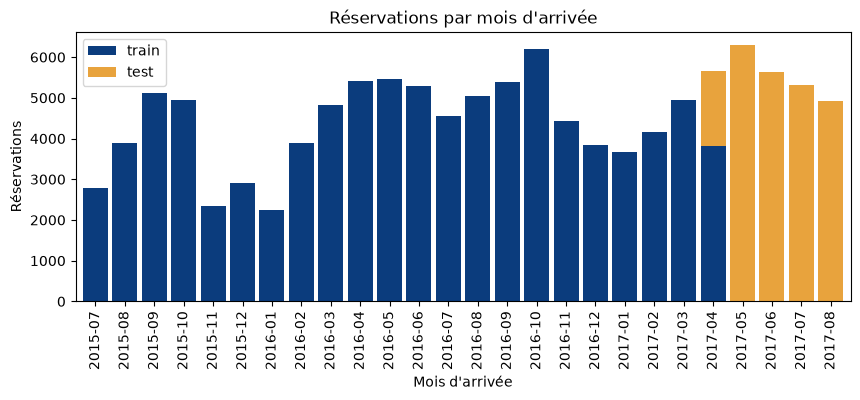

In [15]:
par_mois = pd.DataFrame({
    "train": train["date_arrivee"].dt.to_period("M").value_counts(),
    "test": test["date_arrivee"].dt.to_period("M").value_counts(),
}).sort_index().fillna(0)
ax = par_mois.plot.bar(stacked=True, width=0.85, figsize=(10, 3.5), color=["#0B3C7D", "#E8A33D"])
ax.set(title="Réservations par mois d'arrivée", xlabel="Mois d'arrivée", ylabel="Réservations")
plt.show()

On voit la saison : de 2 248 arrivées en janvier 2016 à 6 305 en mai 2017. Avril 2017 est partagé (3 812 arrivées
au train, 1 841 au test), et le test tombe sur la haute saison.

**Le hasard flatte.** Même pipeline sans fuite, mais découpé au hasard avec `train_test_split(..., stratify=y)`,
avec un test de la même taille.

In [16]:
colonnes = NUMERIQUES + CATEGORIELLES
train_h, test_h = train_test_split(df, test_size=len(test), stratify=df[CIBLE], random_state=0)
au_hasard = boosting_brut(NUMERIQUES, CATEGORIELLES).fit(train_h[colonnes], train_h[CIBLE])
auc_hasard = roc_auc_score(test_h[CIBLE], au_hasard.predict_proba(test_h[colonnes])[:, 1])
print(f"Découpage au hasard : AUC {auc_hasard:.3f}")
print(f"Découpage temporel  : AUC {aucs['sans fuite']:.3f}")

Découpage au hasard : AUC 0.935
Découpage temporel  : AUC 0.873


Au hasard, l'AUC atteint 0,935 ; dans le temps, 0,873. Six centièmes qu'on ne retrouvera jamais en production.

> 💬 **Pourquoi le découpage au hasard donne-t-il un meilleur score ?**
>
> *Piste : le hasard répartit entre le train et le test des réservations d'une même semaine, d'un même groupe : le
> modèle n'a qu'à reconnaître la sœur jumelle qu'il a vue à l'entraînement. En production, on prédit l'avenir, et
> les jumelles n'existent pas encore.*

Vérifions. Une « jumelle » est une réservation du train qui a la même date d'arrivée, le même délai, le même prix,
le même agent et le même pays.

In [17]:
def jumelles(tr, te, cles=("date_arrivee", "lead_time", "adr", "agent", "country")):
    cles = list(cles)
    vues = tr[cles + [CIBLE]].drop_duplicates(cles).rename(columns={CIBLE: "issue_jumelle"})
    paires = te[cles + [CIBLE]].merge(vues, on=cles, how="left")
    trouvee = paires["issue_jumelle"].notna()
    meme_issue = (paires.loc[trouvee, "issue_jumelle"] == paires.loc[trouvee, CIBLE]).mean()
    return {"part du test qui a une jumelle au train": trouvee.mean(), "même issue que sa jumelle": meme_issue}


pd.DataFrame({"au hasard": jumelles(train_h, test_h), "dans le temps": jumelles(train, test)}).round(3)

,au hasard,dans le temps
part du test qui a une jumelle au train,0.385,0.0
même issue que sa jumelle,0.962,NaN


Au hasard, 38,5 % des réservations du test ont une jumelle au train, et 96,2 % d'entre elles ont la même issue
que leur jumelle : le modèle reconnaît le groupe plutôt qu'il ne prédit. Dans le temps, le 0 est garanti par
construction : une jumelle arrive le même jour, et `decouper` ne coupe jamais une journée en deux (d'où le `NaN`
juste en dessous). Seul le découpage au hasard fabrique des jumelles.

Pour régler un modèle sans toucher au test, on valide aussi dans le temps, à l'intérieur du train :
`TimeSeriesSplit` (cours 1, slide 9), qui servira au notebook 03.

In [18]:
plis = []
for numero, (i_app, i_val) in enumerate(TimeSeriesSplit(n_splits=3).split(train), start=1):
    app, val = train["date_arrivee"].iloc[i_app], train["date_arrivee"].iloc[i_val]
    plis.append({"pli": numero, "apprentissage": f"{app.min():%Y-%m-%d} → {app.max():%Y-%m-%d}",
                 "lignes (app.)": len(i_app), "validation": f"{val.min():%Y-%m-%d} → {val.max():%Y-%m-%d}",
                 "lignes (val.)": len(i_val)})
pd.DataFrame(plis).set_index("pli")

,apprentissage,lignes (app.),validation,lignes (val.)
pli,,,,
1,2015-07-01 → 2016-01-27,23799,2016-01-27 → 2016-06-21,23797
2,2015-07-01 → 2016-06-21,47596,2016-06-21 → 2016-11-06,23797
3,2015-07-01 → 2016-11-06,71393,2016-11-06 → 2017-04-21,23797


L'apprentissage grandit (23 799, puis 47 596, puis 71 393 réservations) et la validation, toujours 23 797 lignes,
suit immédiatement. `TimeSeriesSplit` coupe au numéro de ligne : une journée peut tomber des deux côtés (le
27 janvier 2016 est dans les deux parties du pli 1), ce que `decouper` évite.

## 5. Le score à battre et les métriques

Avant de se réjouir d'une AUC de 0,873, on mesure deux modèles naïfs : un `DummyClassifier`, qui donne à toutes les
réservations la même probabilité (le taux d'annulation du train), et une régression logistique sur `lead_time` seul.
Trois mesures, toujours sur le test.

In [19]:
def mesurer(proba):
    return {"AUC ROC": roc_auc_score(y_test, proba),
            "précision moyenne": average_precision_score(y_test, proba),
            "exactitude": accuracy_score(y_test, proba >= 0.5)}


naif = DummyClassifier().fit(train[NUMERIQUES], y_train)
un_seul = make_pipeline(StandardScaler(), LogisticRegression()).fit(train[["lead_time"]], y_train)

In [20]:
probas = {
    "DummyClassifier": naif.predict_proba(test[NUMERIQUES])[:, 1],
    "lead_time seul (rég. logistique)": un_seul.predict_proba(test[["lead_time"]])[:, 1],
    "boosting, colonnes brutes sans fuite": ajustes["sans fuite"].predict_proba(test[colonnes])[:, 1],
}
scores = {}
for nom, proba in probas.items():
    scores[nom] = mesurer(proba)
pd.DataFrame(scores).T.round(3)

,AUC ROC,précision moyenne,exactitude
DummyClassifier,0.500,0.410,0.590
lead_time seul (rég. logistique),0.622,0.487,0.581
"boosting, colonnes brutes sans fuite",0.873,0.834,0.778


Le `DummyClassifier` a une AUC de 0,5 et une exactitude de 0,590 : il prédit toujours « non annulée » et a raison
pour les 59 % de réservations honorées du test. `lead_time` seul monte à 0,622 d'AUC, mais son exactitude (0,581)
est *plus basse* que celle du modèle qui ne fait rien. Le boosting sur les colonnes brutes atteint 0,873 d'AUC,
0,834 de précision moyenne et 0,778 d'exactitude.

**Lire ces mesures.** L'AUC ROC est la probabilité qu'une réservation annulée tirée au hasard reçoive un score plus
haut qu'une réservation honorée tirée au hasard : 0,5, c'est pile ou face ; 1, un classement parfait. La précision
moyenne parcourt les réservations de la plus suspecte à la moins suspecte et fait la moyenne de la précision (la part
de vraies annulées parmi les réservations signalées) à chaque annulée rencontrée ; un score au hasard obtient le
taux d'annulation du test, soit 0,410 (la valeur du `DummyClassifier`). Vérifions la définition de l'AUC en tirant
des paires.

In [21]:
rng = np.random.default_rng(0)
proba = probas["boosting, colonnes brutes sans fuite"]
annulees = rng.choice(proba[y_test.to_numpy() == 1], 200_000)
honorees = rng.choice(proba[y_test.to_numpy() == 0], 200_000)
print(f"Paires bien classées : {(annulees > honorees).mean() + 0.5 * (annulees == honorees).mean():.3f}")
print(f"roc_auc_score        : {roc_auc_score(y_test, proba):.3f}")

Paires bien classées : 0.872
roc_auc_score        : 0.873


Sur 200 000 paires (annulée, honorée), la réservation annulée a le score le plus haut dans 87,2 % des cas, pour
une AUC de 0,873 : au tirage près, c'est la même chose. La courbe ROC montre ce classement seuil par seuil.

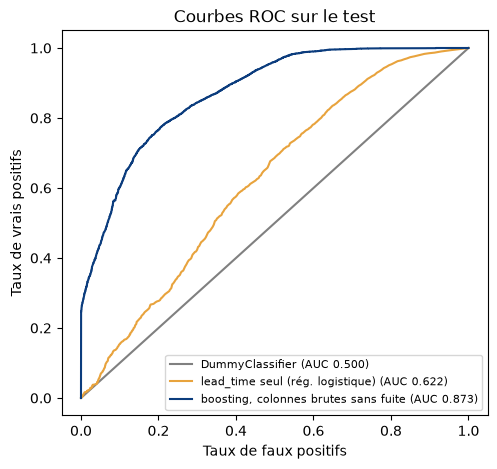

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for (nom, proba), couleur in zip(probas.items(), ["grey", "#E8A33D", "#0B3C7D"]):
    taux_fp, taux_vp, _ = roc_curve(y_test, proba)
    ax.plot(taux_fp, taux_vp, color=couleur, label=f"{nom} (AUC {scores[nom]['AUC ROC']:.3f})")
ax.set(title="Courbes ROC sur le test", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs")
ax.legend(loc="lower right", fontsize=8)
plt.show()

Le `DummyClassifier` suit la diagonale (AUC 0,5), `lead_time` s'en écarte à peine (0,622), le boosting s'en éloigne
nettement (0,873) : plus la courbe monte vite, plus on attrape d'annulations pour peu de fausses alertes. Son
départ vertical (près d'un quart des annulations repérées sans aucune fausse alerte) correspond aux réservations
« Non Refund », presque toutes annulées.

> 💬 **Le modèle `lead_time` a une exactitude plus faible que le `DummyClassifier` (0,581 contre 0,590), mais une
> AUC bien meilleure (0,622 contre 0,5). Lequel est le plus utile à l'hôtel ?**
>
> *Piste : le modèle `lead_time`, qui classe mieux. L'exactitude dépend du seuil 0,5 et du taux de base : avec 41 %
> d'annulées, « personne n'annule » a déjà 59 % de bonnes réponses. L'hôtel choisira son seuil selon le coût d'une
> chambre vide et celui d'un client refoulé ; l'AUC juge le classement avant ce choix.*

**Le score à battre.** Gardez ces chiffres en tête. Dans les notebooks 01 à 04 : mêmes données, même découpage, mêmes métriques ; seule la
préparation des variables change. Un modèle doit d'abord dépasser nettement 0,622 (une seule variable) ; le boosting
sur les colonnes brutes, à 0,873, est la vraie barre : c'est, à peu de chose près, l'approche A.

## À retenir

- **Fixer le moment de la prédiction avant tout.** À la réservation, une colonne remplie après est une fuite, même
  si elle est dans le fichier. `reservation_status` donne une AUC de 1,000 : cette fuite saute aux yeux. Les trois
  fuites discrètes ne font gagner que deux centièmes (de 0,873 à 0,893) : un gain plausible passe inaperçu, et c'est
  ce qui les rend plus dangereuses.
- **Étrange n'est pas interdit.** `deposit_type = "Non Refund"` (99,4 % d'annulations) était connue à la
  réservation : on la garde.
- **Des données datées se découpent dans le temps.** Le hasard donne 0,935 au lieu de 0,873, parce que 38,5 % des
  réservations du test ont une jumelle au train.
- **Un score n'a de sens que comparé à « ne rien faire ».** Le `DummyClassifier` a déjà 59 % d'exactitude : on suit
  l'AUC ROC, complétée par la précision moyenne.
- Ces règles sont rangées dans `fe_tp.donnees` (`FUITES`, `ECARTEES`, `decouper`) : les quatre approches les
  appliquent à l'identique.